# 08 · The PM's daily workflow

**Who this is for:** a PM running the book live. Each morning, once yesterday's close and any new analyst ratings have arrived:

1. rerun the pipeline, using the GARCH cache so it takes seconds;
2. read **today's book** (target and held weights, scores, legs, signal values);
3. generate the **trade list** from the current holdings, in shares and rounded to lots;
4. check the **risk report** (exposures, ex-ante vol and beta, concentration, data freshness);
5. check **signal health** (the realised rolling IC, as an early warning of alpha decay);
6. see **what changed** since yesterday.

Here 'today' is the last session of the shipped open universe.

In [1]:
# fmflow-setup: runs as-is everywhere. In an installed environment it only locates the repository; on Google Colab,
# Binder or a Jupyter without the package, it downloads the repository once and installs it (about a minute).
import importlib, importlib.util, os, shutil, subprocess, sys
from pathlib import Path

REPO_URL = os.environ.get("FMFLOW_REPO_URL", "https://github.com/bahakh19/first-mover-flow")   # set it to use a fork


def _run(cmd: list, what: str, hint: str = "") -> None:
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"{what} failed:\n{(r.stderr or r.stdout).strip()[-1500:]}\n{hint}")


_here = Path.cwd()
_root = next((p for p in (_here, *_here.parents, _here / "first-mover-flow") if (p / "src" / "fmflow").is_dir()), None)
if _root is None:                                                  # notebooks need the repository's data/ folder
    _root = (_here / "first-mover-flow").resolve()
    print(f"Downloading {REPO_URL} ...")
    if shutil.which("git"):
        _run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(_root)], f"git clone {REPO_URL}",
             "Is the repository public? For a fork or a local copy, set the environment variable FMFLOW_REPO_URL.")
    else:                                                          # no git: the GitHub zip archive of the main branch
        import io, urllib.request, zipfile
        with urllib.request.urlopen(REPO_URL.rstrip("/") + "/archive/refs/heads/main.zip") as _r:
            zipfile.ZipFile(io.BytesIO(_r.read())).extractall(_here)
        (_here / (REPO_URL.rstrip("/").split("/")[-1] + "-main")).rename(_root)
if importlib.util.find_spec("fmflow") is None:
    print("Installing fmflow and its dependencies (about a minute) ...")
    _target = f"{_root}[plot]"
    if importlib.util.find_spec("pip"):
        _run([sys.executable, "-m", "pip", "install", "-q", "-e", _target], "pip install")
    elif shutil.which("uv"):                                       # uv-created environments have no pip
        _run(["uv", "pip", "install", "-q", "--python", sys.executable, "-e", _target], "uv pip install")
    else:
        raise RuntimeError("this kernel has neither pip nor uv: install the package from a terminal (INSTALL.md)")
    sys.path.insert(0, str(_root / "src"))
    importlib.invalidate_caches()
os.chdir(_root / "notebooks")
print("fmflow", importlib.import_module("fmflow").__version__, "| repository:", _root)

fmflow 2.2.4 | repository: /home/claude/work/v22/repo


In [2]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fmflow import StrategyConfig, load_prices, load_ratings, run_strategy
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GREEN, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#9a9a9a"
P = load_prices(ROOT / "data/open/MarketData_Normalized.csv")
R = load_ratings(ROOT / "data/open/Ratings_Normalized.csv", P)
SIG = pd.read_csv(ROOT / "tests/fixtures/open_sig_gjr.csv.gz", index_col=0, parse_dates=True)   # cached GARCH forecasts
EV = slice("2024-01-05", "2026-08-05")                                                          # pre-registered window
CFG = StrategyConfig.fmf_n_scalable()                                                           # leg fraction 0.4
out = run_strategy(P, R, CFG, sig_vol=SIG)
print(f"{out.prices.shape[1]} stocks, {len(out.prices)} sessions, {len(out.ratings):,} accepted ratings")
from fmflow.production import latest_book, trade_list, risk_report, signal_monitor

30 stocks, 899 sessions, 2,363 accepted ratings


In [3]:
book = latest_book(out)
print("book date:", book.attrs["date"].date())
display(book.round(4).head(12))

book date: 2026-08-05


,held_weight,target_weight,score,rank,leg,breadth_63,event_breadth_63,breadth_resid_mom,leader_minus_herd,vol_forecast_ann
stock,,,,,,,,,,
stock_28,0.057,0.060,0.395,1.000,long,NaN,NaN,NaN,1.000,0.403
stock_1,0.088,0.059,0.362,2.000,long,1.000,NaN,0.172,1.000,0.412
stock_5,0.049,0.050,0.340,3.000,long,1.000,1.000,0.148,1.000,0.484
stock_23,0.054,0.055,0.310,4.000,long,1.000,1.000,0.218,0.538,0.439
stock_17,0.007,0.138,0.286,5.000,long,1.000,NaN,0.403,0.333,0.176
stock_3,0.032,0.032,0.244,6.000,long,1.000,1.000,-0.037,1.000,0.764
stock_15,0.004,0.028,0.233,7.000,long,1.000,1.000,-0.060,1.000,0.878
stock_29,0.024,0.077,0.226,8.000,long,1.000,NaN,0.009,NaN,0.314
stock_25,0.024,0.000,0.189,9.000,flat,1.000,1.000,-0.014,0.429,0.424


## Trade list

Prices must be in currency for share quantities. The shipped prices are normalised, so the example rescales them to look like real prices. The current holdings are yesterday's book, held at yesterday's NAV.

In [4]:
nav = 25_000_000
px_ccy = out.prices.iloc[-1] * 80                                   # stand-in for real closing prices
yday = out.weights.iloc[-2]
current = np.round(yday * nav / (out.prices.iloc[-2] * 80))
tl = trade_list(book["held_weight"], current, px_ccy, nav=nav, lot_size=1, min_trade_notional=5_000)
display(tl)
print(f"gross traded {tl.attrs['gross_traded']:,.0f} = {100 * tl.attrs['turnover_vs_nav']:.2f}% of NAV "
      "(42 overlapping tranches: about 1/42 of the book changes each day)")

,current_shares,target_shares,trade_shares,trade_notional,side
stock,,,,,
stock_17,644.000,1285.000,641.000,82371.064,BUY
stock_3,1234.000,1319.000,85.000,50694.680,BUY
stock_23,1181.000,1144.000,-37.000,-43995.664,SELL
stock_29,8445.000,9043.000,598.000,39137.904,BUY
stock_21,-2911.000,-3103.000,-192.000,-36834.816,SELL
stock_22,-61361.000,-60087.000,1274.000,35692.384,BUY
stock_1,11298.000,11118.000,-180.000,-35441.280,SELL
stock_5,2015.000,2065.000,50.000,29864.400,BUY
stock_28,10545.000,10757.000,212.000,27843.232,BUY


gross traded 546,190 = 2.18% of NAV (42 overlapping tranches: about 1/42 of the book changes each day)


In [5]:
display(risk_report(out).to_frame("today"))
ytd = risk_report(out, out.weights.index[-2])
print("ex-ante beta yesterday -> today:", round(ytd["ex-ante beta (EW market)"], 3), "->", round(risk_report(out)["ex-ante beta (EW market)"], 3))

,today
date,2026-08-05
gross,0.998
net,-0.000
long names,12
short names,10
largest |w|,0.088
top-3 share of gross,0.234
ex-ante vol (ann.),0.146
ex-ante beta (EW market),0.127
names with valid score,22


ex-ante beta yesterday -> today: 0.126 -> 0.127


## Signal health

The realised IC on day *t* uses only signals from *t − 21* and their completed 21-session returns, so the series is known in real time. A sustained negative reading is the cue to review the model, not to retune it on the fly.

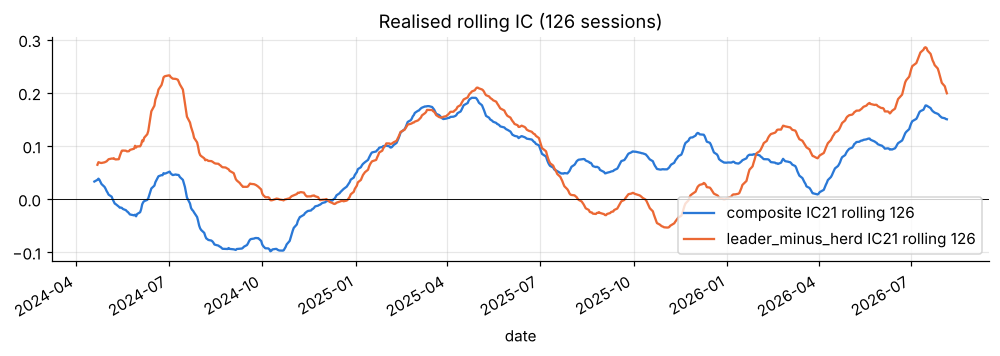

In [6]:
mon = signal_monitor(out, h=21, window=126)
mon.loc["2024":].plot(figsize=(11, 3), color=[BLUE, ORANGE], title="Realised rolling IC (126 sessions)"); plt.axhline(0, color="k", lw=0.6); plt.show()

## What changed since yesterday?

The analyst events that arrived overnight, and the names whose rank moved most.

In [7]:
t, t1 = out.weights.index[-1], out.weights.index[-2]
new = out.ratings[out.ratings["knowledge_date"] == t][["stock", "analyst", "pub_date", "tp", "prev_tp", "revision", "n_same_day"]]
print(f"{len(new)} ratings became usable today"); display(new)
dr = (out.score.loc[t].rank() - out.score.loc[t1].rank()).dropna().sort_values()
display(pd.concat([dr.head(3), dr.tail(3)]).to_frame("rank change"))

1 ratings became usable today


,stock,analyst,pub_date,tp,prev_tp,revision,n_same_day
2362,stock_25,analyst_31,2026-08-04,5.774,5.053,0.134,1


,rank change
stock,
stock_29,-3.000
stock_18,-2.000
stock_5,-1.000
stock_13,1.000
stock_27,1.000
stock_24,1.000


## The production command

```bash
fmflow book --prices prices.csv --ratings ratings.csv --config configs/fmf_n_leg040.json \
            --nav 25e6 --prices-ccy closes.csv --holdings holdings.csv --cache-dir .fmflow_cache
```